In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('Food_Delivery_Times.csv')
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [3]:
df.isnull().sum()

,0
Order_ID,0
Distance_km,0
Weather,30
Traffic_Level,30
Time_of_Day,30
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,30
Delivery_Time_min,0


In [4]:
df.columns

Index(['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day',
       'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs',
       'Delivery_Time_min'],
      dtype='object')

In [5]:
df['Weather'].fillna(df['Weather'].mode()[0], inplace=True)
df['Traffic_Level'].fillna(df['Traffic_Level'].mode()[0], inplace=True)
df['Time_of_Day'].fillna(df['Time_of_Day'].mode()[0], inplace=True)
df['Courier_Experience_yrs'].fillna(df['Courier_Experience_yrs'].median(), inplace=True)

In [6]:
df.isnull().sum()

,0
Order_ID,0
Distance_km,0
Weather,0
Traffic_Level,0
Time_of_Day,0
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,0
Delivery_Time_min,0


In [7]:
df.drop(columns=['Order_ID'],inplace=True)

### 1. Descriptive Statistics and Target Distribution
Let's start by looking at the descriptive statistics of the dataset and plotting the distribution of our target variable `Delivery_Time_min`.

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000,1000,1000,1000,1000.000000,1000.000000,1000.000000
unique,NaN,5,3,4,3,NaN,NaN,NaN
top,NaN,Clear,Medium,Morning,Bike,NaN,NaN,NaN
freq,NaN,500,420,338,503,NaN,NaN,NaN
mean,10.059970,NaN,NaN,NaN,NaN,16.982000,4.592000,56.732000
std,5.696656,NaN,NaN,NaN,NaN,7.204553,2.871198,22.070915
min,0.590000,NaN,NaN,NaN,NaN,5.000000,0.000000,8.000000
25%,5.105000,NaN,NaN,NaN,NaN,11.000000,2.000000,41.000000
50%,10.190000,NaN,NaN,NaN,NaN,17.000000,5.000000,55.500000
75%,15.017500,NaN,NaN,NaN,NaN,23.000000,7.000000,71.000000


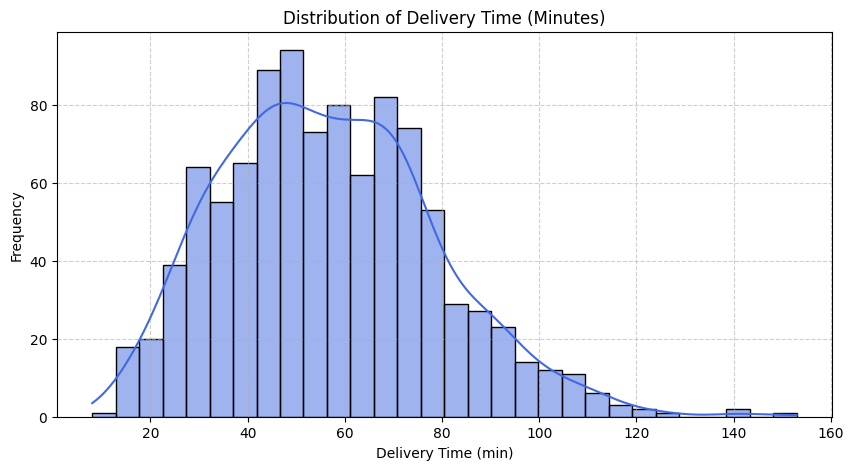

In [8]:
# Display descriptive statistics
display(df.describe(include='all'))

# Plot distribution of the target variable
plt.figure(figsize=(10, 5))
sns.histplot(df['Delivery_Time_min'], kde=True, bins=30, color='royalblue')
plt.title('Distribution of Delivery Time (Minutes)')
plt.xlabel('Delivery Time (min)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 2. Numerical Features vs. Target Variable
Let's visualize how the numerical features (`Distance_km`, `Preparation_Time_min`, `Courier_Experience_yrs`) correlate with `Delivery_Time_min` using scatter plots and a correlation heatmap.

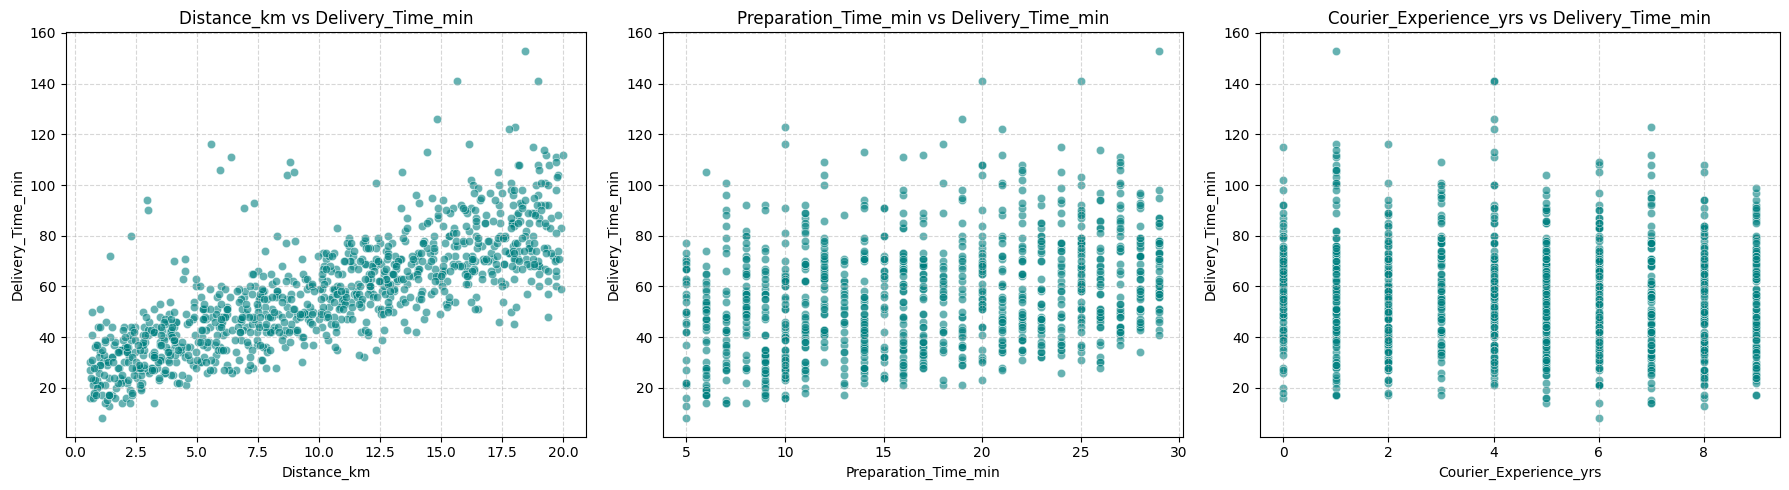

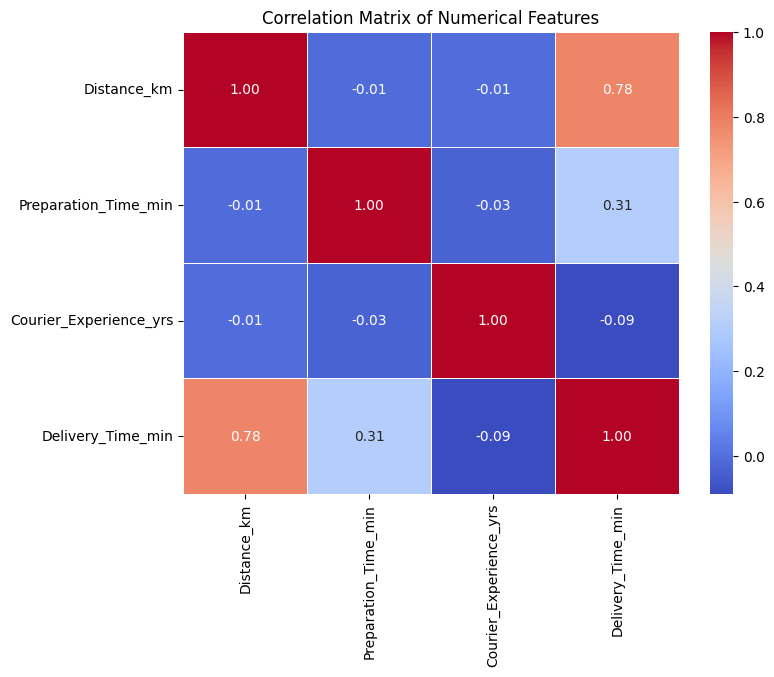

In [9]:
# Relationship between numerical columns and Delivery Time
num_cols = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(num_cols):
    sns.scatterplot(data=df, x=col, y='Delivery_Time_min', alpha=0.6, ax=axes[i], color='teal')
    axes[i].set_title(f'{col} vs Delivery_Time_min')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Heatmap of correlation
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols + ['Delivery_Time_min']].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

### 3. Categorical Features vs. Target Variable
Now let's see how different factors like `Weather`, `Traffic_Level`, `Time_of_Day`, and `Vehicle_Type` influence the delivery times.

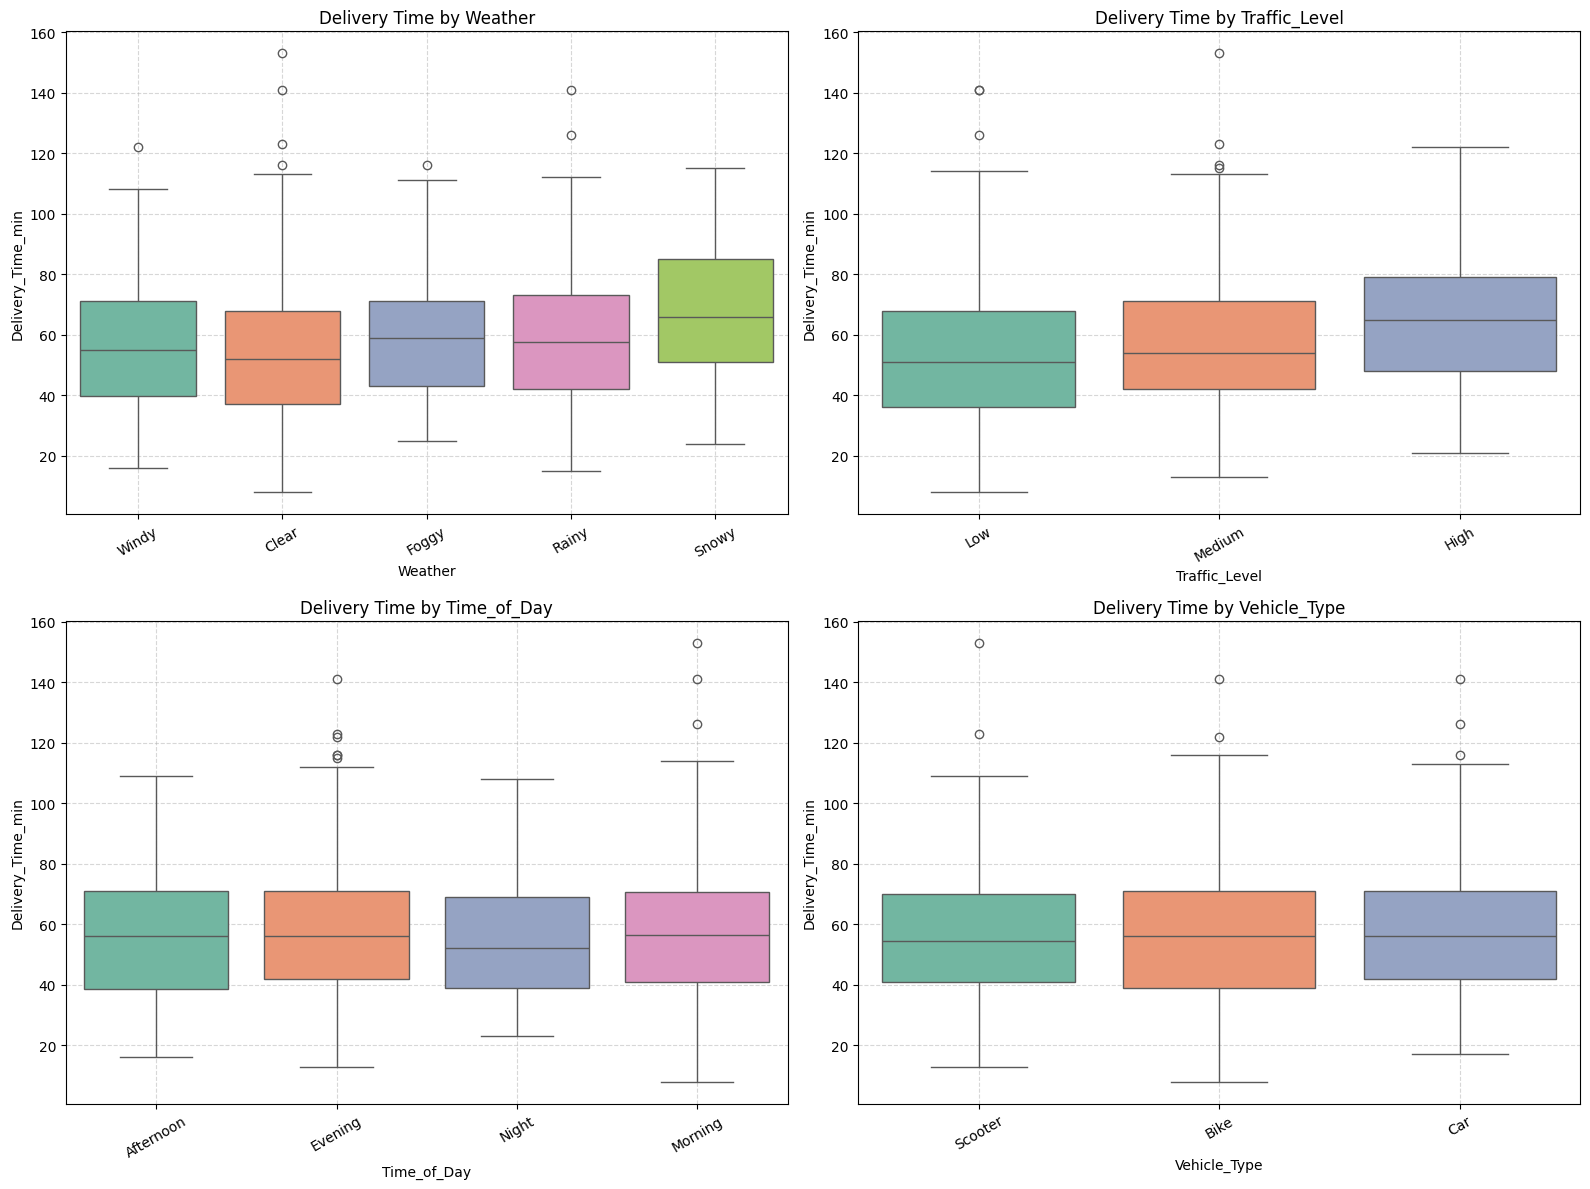

In [10]:
cat_cols = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.boxplot(data=df, x=col, y='Delivery_Time_min', ax=axes[i], palette='Set2')
    axes[i].set_title(f'Delivery Time by {col}')
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=30)
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Statistical Testing for Feature Selection
To find the "best" features quantitatively, we will use:
- **Pearson Correlation Test** for continuous numerical features (`Distance_km`, `Preparation_Time_min`, `Courier_Experience_yrs`) to test if they have a significant linear relationship with `Delivery_Time_min`.
- **One-way ANOVA (Analysis of Variance)** for categorical features (`Weather`, `Traffic_Level`, `Time_of_Day`, `Vehicle_Type`) to test if the mean delivery times vary significantly across different categories.

In [11]:
import scipy.stats as stats
import pandas as pd

print("=== Statistical Testing for Numerical Features (Pearson Correlation) ===")
num_features = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']
numerical_results = []

for col in num_features:
    corr, p_val = stats.pearsonr(df[col], df['Delivery_Time_min'])
    numerical_results.append({'Feature': col, 'Correlation': corr, 'p-value': p_val})

num_results_df = pd.DataFrame(numerical_results)

# ---> Add this line to force standard decimal notation (e.g., 5 decimal places)
pd.set_option('display.float_format', lambda x: '%.5f' % x)

display(num_results_df.sort_values(by='p-value'))


=== Statistical Testing for Numerical Features (Pearson Correlation) ===


,Feature,Correlation,p-value
0,Distance_km,0.78100,0.00000
1,Preparation_Time_min,0.30735,0.00000
2,Courier_Experience_yrs,-0.08911,0.00480


In [12]:
import scipy.stats as stats
import pandas as pd

print("\n=== Statistical Testing for Categorical Features (One-Way ANOVA) ===")
cat_features = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']
categorical_results = []

for col in cat_features:
    # Group delivery times by each category, dropping missing values to prevent ANOVA errors
    groups = [group['Delivery_Time_min'].dropna().values for name, group in df.groupby(col)]

    # Perform One-Way ANOVA (only if we have groups to compare)
    if len(groups) > 1:
        f_stat, p_val = stats.f_oneway(*groups)
        categorical_results.append({'Feature': col, 'F-Statistic': f_stat, 'p-value': p_val})

cat_results_df = pd.DataFrame(categorical_results)

# Force Pandas to display clean decimals (5 decimal places) instead of scientific notation
pd.set_option('display.float_format', lambda x: '%.5f' % x)

display(cat_results_df.sort_values(by='p-value'))



=== Statistical Testing for Categorical Features (One-Way ANOVA) ===


,Feature,F-Statistic,p-value
1,Traffic_Level,19.75134,0.00000
0,Weather,10.49906,0.00000
3,Vehicle_Type,0.58937,0.55487
2,Time_of_Day,0.34677,0.79151


### 4. Splitting Data into Features (X) and Target (y), followed by Train-Test Split
Let's isolate our target variable `Delivery_Time_min` into `y` and our features into `X`. Then, we will split them into training and testing sets using an 80/20 split.

### 4. Label Encoding Categorical Features
We will encode our categorical columns using `LabelEncoder` from `scikit-learn` before splitting our features and target variable.

In [15]:
from sklearn.preprocessing import LabelEncoder

# Identify categorical columns to encode
cat_cols = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']

# Initialize a dictionary to store encoders for each column if needed later
encoders = {}

# Create a copy of the dataframe to keep original intact
df_encoded = df.copy()

# Apply LabelEncoder to each categorical column
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le

# Display the first few rows of the encoded dataframe
display(df.head())

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,7.93000,4,1,0,2,12,1.00000,43
1,16.42000,0,2,1,0,20,2.00000,84
2,9.52000,1,1,3,2,28,1.00000,59
3,7.44000,2,2,0,2,5,1.00000,37
4,19.03000,0,1,2,0,16,5.00000,68


In [16]:
X = df.drop(columns=['Delivery_Time_min'])
y = df['Delivery_Time_min']

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(800, 7)
(200, 7)
(800,)
(200,)


In [24]:
from sklearn.tree import DecisionTreeRegressor

model_dt = DecisionTreeRegressor(random_state=42)
model_dt.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [25]:
y_pred = model_dt.predict(X_test)

from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
import numpy as np
print('MAE:', mean_absolute_error(y_test, y_pred))
print('MSE:', mean_squared_error(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))
print('r2_score:',r2_score(y_test, y_pred))

MAE: 10.56
MSE: 226.82
RMSE: 15.060544478869282
r2_score: 0.4939617366848571


### 5. Training and Evaluating Random Forest Regressor
Now we will train a `RandomForestRegressor` with default hyperparameters on our training data and measure its performance metrics (`MAE`, `MSE`, `RMSE`, `R2 Score`) on the test set.

In [26]:
from sklearn.ensemble import RandomForestRegressor

# Initialize and fit the Random Forest model with default parameters
model_rf = RandomForestRegressor(random_state=42)
model_rf.fit(X_train, y_train)

# Make predictions on the test set
y_pred_rf = model_rf.predict(X_test)

# Print evaluation metrics
print('=== Random Forest Evaluation ===')
print('MAE:', mean_absolute_error(y_test, y_pred_rf))
print('MSE:', mean_squared_error(y_test, y_pred_rf))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print('r2_score:', r2_score(y_test, y_pred_rf))

=== Random Forest Evaluation ===
MAE: 7.0645500000000006
MSE: 100.1170135
RMSE: 10.005848964480725
r2_score: 0.7766376878589246


### 6. Hyperparameter Tuning for Random Forest
To find the optimal hyperparameters for our `RandomForestRegressor`, we will perform a grid search with 5-fold cross-validation over several values of `n_estimators`, `max_depth`, and `min_samples_split`.

### 8. Hyperparameter Tuning using RandomizedSearchCV
Let's define a broader parameter distribution and use `RandomizedSearchCV` to optimize the `RandomForestRegressor`.

In [27]:
from sklearn.model_selection import RandomizedSearchCV

# Define parameter distributions to sample from
param_distributions = {
    'n_estimators': [50, 100, 150, 200, 300],
    'max_features' : ['auto', 'sqrt', 'log2'],
    'max_depth': [None, 10, 20, 30, 40],
    'min_samples_split': [2, 5, 10, 15],
    'min_samples_leaf': [1, 2, 4, 8]
}

# Initialize the base Random Forest model
rf_base = RandomForestRegressor(random_state=42)

# Initialize RandomizedSearchCV
random_search = RandomizedSearchCV(estimator=rf_base, param_distributions=param_distributions,
                                   n_iter=20, cv=5, scoring='r2', n_jobs=-1, random_state=42, verbose=1)

# Fit the randomized search to the training data
random_search.fit(X_train, y_train)

# Extract the best model and parameters
best_rf_random = random_search.best_estimator_
print("Best Parameters Found (Randomized Search):", random_search.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters Found (Randomized Search): {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 10}


### 9. Evaluating the Randomized Search Model
Let's evaluate the performance of our randomized-search tuned Random Forest model on the test dataset.

In [28]:
# Predict using the best randomized search model
y_pred_random = best_rf_random.predict(X_test)

# Print evaluation metrics for the tuned model
print('=== Randomized Search Random Forest Evaluation ===')
print('MAE:', mean_absolute_error(y_test, y_pred_random))
print('MSE:', mean_squared_error(y_test, y_pred_random))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred_random)))
print('r2_score:', r2_score(y_test, y_pred_random))

=== Randomized Search Random Forest Evaluation ===
MAE: 7.257463063243689
MSE: 97.45460335524163
RMSE: 9.8719098129613
r2_score: 0.7825775582666759


### 10. Implement the Finalized Tuned Random Forest Model
We will initialize a new `RandomForestRegressor` with the exact best hyperparameters found by our randomized search, fit it on the entire training set, and evaluate the performance.

In [31]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Instantiate the optimized model with the best parameters
final_rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=2,
    max_features='log2',
    random_state=42
)

# Fit the model on the training data
final_rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_final = final_rf_model.predict(X_test)

# Compute evaluation metrics
mae = mean_absolute_error(y_test, y_pred_final)
mse = mean_squared_error(y_test, y_pred_final)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_final)

# Print the results
print('=== Optimized Random Forest Performance ===')
print(f'Mean Absolute Error (MAE): {mae:.4f}')
print(f'Mean Squared Error (MSE): {mse:.4f}')
print(f'Root Mean Squared Error (RMSE): {rmse:.4f}')
print(f'R2 Score (Coefficient of Determination): {r2:.4f}')

=== Optimized Random Forest Performance ===
Mean Absolute Error (MAE): 7.2575
Mean Squared Error (MSE): 97.4546
Root Mean Squared Error (RMSE): 9.8719
R2 Score (Coefficient of Determination): 0.7826


### 11. Save the Model and Label Encoders using Pickle
We will save the optimized `final_rf_model` along with the `encoders` dictionary as `.pkl` files to enable seamless deployment.

In [32]:
import pickle

# Save the final trained Random Forest model
with open('final_rf_model.pkl', 'wb') as model_file:
    pickle.dump(final_rf_model, model_file)

# Save the dictionary of Label Encoders
with open('label_encoders.pkl', 'wb') as encoders_file:
    pickle.dump(encoders, encoders_file)

print("Pickle files saved successfully:")
print("- 'final_rf_model.pkl'")
print("- 'label_encoders.pkl'")

Pickle files saved successfully:
- 'final_rf_model.pkl'
- 'label_encoders.pkl'
